# Highway Network on CIFAR10

Assignment #1 — train a convolutional Highway Network (Srivastava et al., 2015) on CIFAR10.

**Before running:** Runtime → Change runtime type → **GPU** (T4 is fine).

Run the cells top to bottom.

## 1. Get the code onto Colab

**Option A — git clone (recommended, if the project is on GitHub).**
Edit the URL to your repo, then run. If the files live in a subfolder, `cd` into it.

In [3]:
# Option A: clone from GitHub
!git clone git@github.com:majowyporanek/deep_learning.git
# If model.py etc. are in a subfolder, move into it (edit to match your repo layout):
# %cd <YOUR_REPO>/HighwayNetwork
!ls

Cloning into 'deep_learning'...
Host key verification failed.
fatal: Could not read from remote repository.

Please make sure you have the correct access rights
and the repository exists.
sample_data


In [4]:
# Option B: manual upload (use ONLY if you are not cloning).
# Run this, then pick model.py, data.py, train.py, utils.py from your computer.
# from google.colab import files
# up = files.upload()

In [7]:
import os
os.chdir('/content')
if not os.path.isdir('deep_learning'):
    !git clone https://github.com/majowyporanek/deep_learning.git
os.chdir('/content/deep_learning/HighwayNetwork')
print('jestem w:', os.getcwd())
print(os.listdir())

Cloning into 'deep_learning'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 14 (delta 0), reused 11 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 494.28 KiB | 29.08 MiB/s, done.
jestem w: /content/deep_learning/HighwayNetwork
['README.md', 'model.py', 'train.py', 'highway_colab.ipynb', 'data.py', 'utils.py']


## 2. Check the GPU

In [8]:
import torch
print('torch', torch.__version__)
print('GPU available:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - set Runtime to GPU!')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

torch 2.14.1+cu130
GPU available: True
GPU: Tesla T4


## 3. Imports + reproducible seed

In [9]:
from model import HighwayConvNet
from data import get_dataloaders
from train import fit, evaluate
from utils import set_seed, count_parameters, plot_history, plot_comparison
import torch.nn as nn

set_seed(42)

## 4. Data (downloads CIFAR10, ~170 MB, first time only)

In [10]:
train_loader, val_loader, test_loader, (mean, std) = get_dataloaders(batch_size=128, num_workers=2)
print('train-only mean:', mean.tolist())
print('train-only std: ', std.tolist())
print('batches  train:', len(train_loader), ' val:', len(val_loader), ' test:', len(test_loader))

100%|██████████| 170M/170M [16:38<00:00, 171kB/s]


train-only mean: [0.4913501441478729, 0.4821614623069763, 0.44659730792045593]
train-only std:  [0.24704869091510773, 0.24355383217334747, 0.26168447732925415]
batches  train: 352  val: 40  test: 79


## 5. Train the Highway network

`blocks_per_stage=3` → ~10 layers. On a T4 expect ~1–1.5 min/epoch, so ~40 epochs ≈ 40–60 min.
The best model (by val accuracy) is saved to `highway.pt`.

In [11]:
highway = HighwayConvNet(mode='highway', blocks_per_stage=3, gate_bias=-2.0)
print('params:', f'{count_parameters(highway):,}')

hist_highway = fit(highway, train_loader, val_loader, device,
                   epochs=40, lr=0.1, weight_decay=5e-4, ckpt_path='highway.pt')

params: 1,257,098
epoch   1/40 | train loss 1.995 acc 0.234 | val loss 1.714 acc 0.358  <- best
epoch   2/40 | train loss 1.644 acc 0.381 | val loss 1.605 acc 0.425  <- best
epoch   3/40 | train loss 1.431 acc 0.477 | val loss 1.314 acc 0.530  <- best
epoch   4/40 | train loss 1.243 acc 0.553 | val loss 1.217 acc 0.576  <- best
epoch   5/40 | train loss 1.121 acc 0.600 | val loss 1.060 acc 0.623  <- best
epoch   6/40 | train loss 1.031 acc 0.634 | val loss 0.988 acc 0.659  <- best
epoch   7/40 | train loss 0.949 acc 0.665 | val loss 0.898 acc 0.689  <- best
epoch   8/40 | train loss 0.885 acc 0.689 | val loss 0.868 acc 0.704  <- best
epoch   9/40 | train loss 0.827 acc 0.709 | val loss 0.834 acc 0.712  <- best
epoch  10/40 | train loss 0.763 acc 0.733 | val loss 0.707 acc 0.769  <- best
epoch  11/40 | train loss 0.712 acc 0.753 | val loss 0.758 acc 0.746
epoch  12/40 | train loss 0.678 acc 0.765 | val loss 0.718 acc 0.755
epoch  13/40 | train loss 0.647 acc 0.774 | val loss 0.642 acc 0

## 6. Training curves

saved plot to highway_curves.png


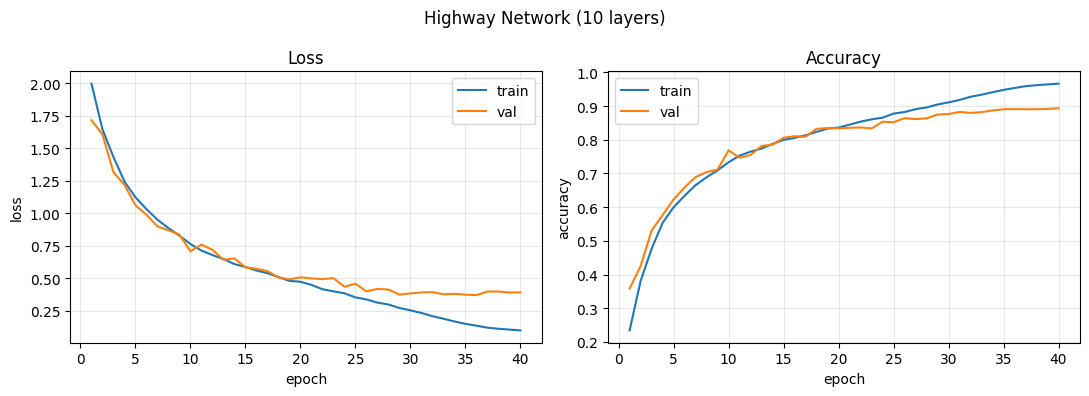

In [12]:
plot_history(hist_highway, title='Highway Network (10 layers)', save_path='highway_curves.png');

## 7. Final test accuracy (touch the test set ONCE)

Load the best saved model, then report test accuracy — this is your headline number.

In [13]:
highway.load_state_dict(torch.load('highway.pt'))
test_loss, test_acc = evaluate(highway, test_loader, device, nn.CrossEntropyLoss())
print(f'TEST accuracy: {test_acc:.4f}   (loss {test_loss:.3f})')

TEST accuracy: 0.8877   (loss 0.423)


## 8. (Day 4) Plain vs Highway — the paper's point

Train a **plain** net with the same architecture and compare. For the real effect,
re-run both at a larger depth (e.g. `blocks_per_stage=8`): plain should degrade, highway shouldn't.

In [14]:
set_seed(42)
plain = HighwayConvNet(mode='plain', blocks_per_stage=3)
print('params:', f'{count_parameters(plain):,}')
hist_plain = fit(plain, train_loader, val_loader, device,
                 epochs=40, lr=0.1, weight_decay=5e-4, ckpt_path='plain.pt')

params: 675,818
epoch   1/40 | train loss 2.305 acc 0.099 | val loss 2.304 acc 0.099  <- best
epoch   2/40 | train loss 2.304 acc 0.101 | val loss 2.304 acc 0.096
epoch   3/40 | train loss 2.305 acc 0.101 | val loss 2.303 acc 0.102  <- best
epoch   4/40 | train loss 2.304 acc 0.098 | val loss 2.303 acc 0.106  <- best
epoch   5/40 | train loss 2.305 acc 0.099 | val loss 2.305 acc 0.106  <- best
epoch   6/40 | train loss 2.304 acc 0.099 | val loss 2.304 acc 0.097
epoch   7/40 | train loss 2.304 acc 0.099 | val loss 2.304 acc 0.104
epoch   8/40 | train loss 2.304 acc 0.100 | val loss 2.303 acc 0.106  <- best
epoch   9/40 | train loss 2.304 acc 0.100 | val loss 2.303 acc 0.097
epoch  10/40 | train loss 2.304 acc 0.100 | val loss 2.303 acc 0.102
epoch  11/40 | train loss 2.304 acc 0.097 | val loss 2.303 acc 0.103
epoch  12/40 | train loss 2.304 acc 0.099 | val loss 2.303 acc 0.096
epoch  13/40 | train loss 2.304 acc 0.099 | val loss 2.304 acc 0.096
epoch  14/40 | train loss 2.304 acc 0.098 

saved plot to compare.png


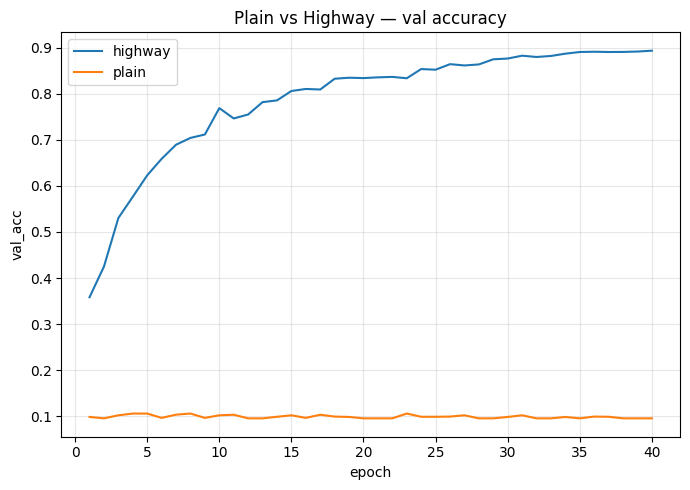

In [15]:
plot_comparison({'highway': hist_highway, 'plain': hist_plain},
                metric='val_acc', title='Plain vs Highway — val accuracy',
                save_path='compare.png');